<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/10_clima/12_clima_chirps_celda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 12 · Lluvia media por celda de 2 km (CHIRPS)

**Autora:** Michelle

**Pregunta:** ¿cuánto llueve en promedio en cada celda de la grilla común, en el año y en la temporada seca?

**Para qué sirve:** es la capa de clima de la integración por celda (cuadernos 60 a 63). Permite comparar la lluvia con el fuego, la expansión agropecuaria y el pH del suelo en la misma unidad espacial.

**Entradas:**
- CHIRPS Daily v2.0 en Google Earth Engine (`UCSB-CHG/CHIRPS/DAILY`), píxeles de 0,05° (~5,5 km).
- `datos/comunes/grilla_2km.gpkg` (cuaderno 02, DVC): 34.763 celdas con `id_celda`.
- `datos/comunes/altillanura_municipios.gpkg` (cuaderno 01, DVC) y `datos/comunes/chirps_mensual_municipio.csv` (cuaderno 11), para validar.

**Salidas:**
- `datos/comunes/lluvia_celda.csv` (DVC): una fila por `id_celda`.
- `modulos/clima_fuego/resultados/12_chirps_climatologia.npz`: la malla de Earth Engine guardada, para no volver a consultarla.
- `modulos/clima_fuego/resultados/12_validacion_municipal.csv` y `modulos/clima_fuego/graficas/12_lluvia_celda.png`.

**Variables por celda (mm):**

| Columna | Qué es |
|---|---|
| `lluvia_anual_1991_2020` | Lluvia media anual, normal climatológica 1991–2020 (estándar de la OMM) |
| `lluvia_seca_1991_2020` | Lluvia media de diciembre a marzo, misma normal |
| `lluvia_anual_2003_2025` | Lluvia media anual en el mismo periodo de los focos de fuego |
| `lluvia_seca_2003_2025` | Lluvia media de diciembre a marzo, 2003–2025 |
| `frac_seca_1991_2020` | Fracción de la lluvia anual que cae de diciembre a marzo |

## Paso 1. Preparar el entorno

In [1]:
# Rutas del proyecto: funcionan en Colab y en local (ver 00_configuracion)
import os, sys, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # Los datos crudos pesados (MGN, CSV de FIRMS, copia del ONI) siguen en Drive
    CRUDOS = '/content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos'
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        !git clone -q {REPO} {RAIZ}
    # Mientras el PR #3 no esté unido a main, los datos comunes están en esta rama
    if not os.path.exists(f'{RAIZ}/datos/comunes/oni_mensual.csv'):
        !git -C {RAIZ} fetch -q origin feature/clima-fuego-datos
        !git -C {RAIZ} checkout -q feature/clima-fuego-datos
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/
    CRUDOS = os.path.join(RAIZ, 'datos', 'crudos')

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
GRAFICAS = os.path.join(RAIZ, 'modulos', 'clima_fuego', 'graficas')
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    """Baja de DVC un archivo pesado del repo (por ejemplo un .gpkg) si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

print('Raíz del repo:', RAIZ)
print('Crudos:', CRUDOS, '| existe:', os.path.exists(CRUDOS))

RESULTADOS = os.path.join(RAIZ, 'modulos', 'clima_fuego', 'resultados')
os.makedirs(RESULTADOS, exist_ok=True)

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import Transformer
from scipy.interpolate import RegularGridInterpolator

traer('datos/comunes/grilla_2km.gpkg')
traer('datos/comunes/altillanura_municipios.gpkg')
grilla = gpd.read_file(f'{COMUNES}/grilla_2km.gpkg')
mpios = gpd.read_file(f'{COMUNES}/altillanura_municipios.gpkg').to_crs(9377)
print(f'Celdas: {len(grilla):,} | CRS: {grilla.crs} | columnas: {list(grilla.columns)}')

Mounted at /content/drive
Raíz del repo: /content/Proyecto-ALTILLANURA
Crudos: /content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos | existe: True
Bajado de DVC: datos/comunes/grilla_2km.gpkg
Bajado de DVC: datos/comunes/altillanura_municipios.gpkg
Celdas: 34,763 | CRS: EPSG:9377 | columnas: ['id_celda', 'mpio_cdpmp', 'mpio_cnmbr', 'area_km2', 'frac_celda', 'x_9377', 'y_9377', 'geometry']


## Paso 2. Climatología de CHIRPS en Earth Engine

**Cómo se calcula.** CHIRPS da la lluvia de cada día en píxeles de 0,05°. En Earth Engine se calculan cuatro mapas (bandas):

1. **Lluvia media anual**: el promedio de la lluvia diaria en el periodo, multiplicado por 365,25 días.
2. **Lluvia media de la temporada seca**: el promedio de la lluvia diaria solo en diciembre, enero, febrero y marzo (`calendarRange(12, 3, 'month')`), multiplicado por los 121,25 días que suman esos meses en promedio.

$$\text{lluvia anual} = \overline{P}_{\text{diaria}} \times 365{,}25 \qquad \text{lluvia seca} = \overline{P}_{\text{diaria, dic–mar}} \times 121{,}25$$

Promediar la lluvia diaria y multiplicar por el número de días da el mismo total medio que sumar cada año y promediar los años, pero en una sola operación.

Cada mapa se calcula para dos periodos: la **normal 1991–2020** y **2003–2025**, el periodo de los focos (Terra + Aqua).

**Descarga.** Con `ee.data.computePixels` se trae la malla de CHIRPS sobre la Altillanura (más un margen de 0,2°) en su **resolución original** de 0,05° y alineada con sus píxeles, para no remuestrear en Earth Engine. Es una malla pequeña (~130 × 70 píxeles por banda). Se guarda en un `.npz` y, si ya existe, se carga sin volver a consultar Earth Engine.

In [2]:
CACHE = f'{RESULTADOS}/12_chirps_climatologia.npz'
BANDAS = ['anual_1991_2020', 'seca_1991_2020', 'anual_2003_2025', 'seca_2003_2025']
RES = 0.05

if os.path.exists(CACHE):
    z = np.load(CACHE)
    malla = {b: z[b] for b in BANDAS}
    lon0, lat1 = float(z['lon0']), float(z['lat1'])
    print('Malla cargada desde', CACHE)
else:
    import ee
    try:
        ee.Initialize(project='altillanura-stdg')
    except Exception:
        ee.Authenticate()
        ee.Initialize(project='altillanura-stdg')

    lon_min, lat_min, lon_max, lat_max = mpios.to_crs(4326).total_bounds
    lon0 = np.floor((lon_min - 0.2) / RES) * RES
    lat1 = np.ceil((lat_max + 0.2) / RES) * RES
    ancho = int(np.ceil((lon_max + 0.2 - lon0) / RES))
    alto = int(np.ceil((lat1 - (lat_min - 0.2)) / RES))

    chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').select('precipitation')
    def media(ini, fin, seca):
        c = chirps.filterDate(ini, fin)
        if seca:
            c = c.filter(ee.Filter.calendarRange(12, 3, 'month'))
        return c.mean().multiply(121.25 if seca else 365.25)
    img = ee.Image.cat([
        media('1991-01-01', '2021-01-01', False).rename('anual_1991_2020'),
        media('1991-01-01', '2021-01-01', True).rename('seca_1991_2020'),
        media('2003-01-01', '2026-01-01', False).rename('anual_2003_2025'),
        media('2003-01-01', '2026-01-01', True).rename('seca_2003_2025'),
    ])
    arr = ee.data.computePixels({
        'expression': img,
        'fileFormat': 'NUMPY_NDARRAY',
        'grid': {'dimensions': {'width': ancho, 'height': alto},
                 'affineTransform': {'scaleX': RES, 'shearX': 0, 'translateX': lon0,
                                     'shearY': 0, 'scaleY': -RES, 'translateY': lat1},
                 'crsCode': 'EPSG:4326'},
    })
    malla = {b: np.asarray(arr[b], dtype='float64') for b in BANDAS}
    np.savez_compressed(CACHE, lon0=lon0, lat1=lat1, **malla)
    print('Descargado de Earth Engine y guardado en', CACHE)

alto, ancho = malla[BANDAS[0]].shape
print(f'Malla: {alto} × {ancho} píxeles de {RES}° | esquina NO: lon {lon0:.2f}, lat {lat1:.2f}')
for b in BANDAS:
    print(f'  {b:16s}: {np.nanmin(malla[b]):7.0f} a {np.nanmax(malla[b]):7.0f} mm')

Descargado de Earth Engine y guardado en /content/Proyecto-ALTILLANURA/modulos/clima_fuego/resultados/12_chirps_climatologia.npz
Malla: 81 × 126 píxeles de 0.05° | esquina NO: lon -73.50, lat 6.55
  anual_1991_2020 :     670 a    4354 mm
  seca_1991_2020  :      60 a     831 mm
  anual_2003_2025 :     699 a    4367 mm
  seca_2003_2025  :      55 a     871 mm


## Paso 3. Llevar la lluvia a cada celda de 2 km

**Cómo se calcula.** Las celdas (2 km) son más pequeñas que los píxeles de CHIRPS (~5,5 km), así que asignarle a cada celda "el píxel donde cae" haría un mapa de bloques, con saltos bruscos en los bordes de cada píxel. En su lugar se usa **interpolación bilineal**:

1. Se toma el centroide de cada celda (`x_9377`, `y_9377`, en metros) y se convierte a longitud y latitud con `pyproj`.
2. Se ubican los 4 píxeles de CHIRPS más cercanos a ese punto (sus centros).
3. El valor de la celda es el promedio de esos 4 valores, ponderado por la cercanía en cada eje (`RegularGridInterpolator` con método lineal).

Así la lluvia varía suavemente entre celdas vecinas, como la lluvia real, y no se inventa detalle que CHIRPS no tiene: la resolución efectiva sigue siendo la de CHIRPS (~5 km).

In [3]:
lat_centros = lat1 - (np.arange(alto) + 0.5) * RES      # de norte a sur
lon_centros = lon0 + (np.arange(ancho) + 0.5) * RES
a_geo = Transformer.from_crs(9377, 4326, always_xy=True)
lon_c, lat_c = a_geo.transform(grilla['x_9377'].values, grilla['y_9377'].values)

lluvia = pd.DataFrame({'id_celda': grilla['id_celda'].values})
for b in BANDAS:
    f = RegularGridInterpolator((lat_centros[::-1], lon_centros), malla[b][::-1, :],
                                method='linear', bounds_error=False, fill_value=np.nan)
    lluvia[f'lluvia_{b}'] = f(np.column_stack([lat_c, lon_c]))
lluvia['frac_seca_1991_2020'] = lluvia['lluvia_seca_1991_2020'] / lluvia['lluvia_anual_1991_2020']

assert lluvia['id_celda'].is_unique and len(lluvia) == len(grilla)
print('Celdas sin valor (debe ser 0):', int(lluvia.drop(columns='id_celda').isna().any(axis=1).sum()))
print(lluvia.drop(columns='id_celda').describe().round(1).to_string())

Celdas sin valor (debe ser 0): 0
       lluvia_anual_1991_2020  lluvia_seca_1991_2020  lluvia_anual_2003_2025  lluvia_seca_2003_2025  frac_seca_1991_2020
count                 34763.0                34763.0                 34763.0                34763.0              34763.0
mean                   2741.6                  310.8                  2737.1                  306.4                  0.1
std                     209.7                  110.8                   202.5                  110.4                  0.0
min                    2177.9                   66.7                  2193.4                   62.4                  0.0
25%                    2598.9                  229.0                  2595.2                  224.3                  0.1
50%                    2744.3                  311.2                  2755.3                  312.4                  0.1
75%                    2908.9                  406.1                  2885.8                  396.8                  0.1

## Paso 4. Validación contra el cuaderno 11

El cuaderno 11 calculó la normal 1991–2020 **por municipio** con otro método: promedio de los píxeles de CHIRPS dentro de cada municipio, en Earth Engine. Si este cuaderno está bien, el promedio de las celdas de cada municipio, **ponderado por el área de cada celda** (`area_km2`, porque las celdas del borde son más pequeñas), debe dar casi lo mismo.

Se espera una diferencia de pocos puntos porcentuales: los dos métodos tratan distinto los bordes y la interpolación.

In [4]:
chirps_m = pd.read_csv(f'{COMUNES}/chirps_mensual_municipio.csv', dtype={'mpio_cdpmp': str})
chirps_m['mes_num'] = chirps_m['mes'].str[5:7].astype(int)
normales = chirps_m.drop_duplicates(['mpio_cdpmp', 'mes_num'])
ref = pd.DataFrame({
    'anual_c11': normales.groupby('mpio_cdpmp')['normal_mm'].sum(),
    'seca_c11': normales[normales['mes_num'].isin([12, 1, 2, 3])].groupby('mpio_cdpmp')['normal_mm'].sum(),
})

g = grilla[['id_celda', 'mpio_cdpmp', 'mpio_cnmbr', 'area_km2']].merge(lluvia, on='id_celda')
pond = lambda col: (g[col] * g['area_km2']).groupby(g['mpio_cdpmp']).sum() / g.groupby('mpio_cdpmp')['area_km2'].sum()
val = pd.DataFrame({'municipio': g.groupby('mpio_cdpmp')['mpio_cnmbr'].first(),
                    'anual_celdas': pond('lluvia_anual_1991_2020'),
                    'seca_celdas': pond('lluvia_seca_1991_2020')}).join(ref)
val['dif_anual_%'] = (val['anual_celdas'] / val['anual_c11'] - 1) * 100
val['dif_seca_%'] = (val['seca_celdas'] / val['seca_c11'] - 1) * 100
print(val.round(1).to_string())
print(f"\nDiferencia máxima: anual {val['dif_anual_%'].abs().max():.1f} %, temporada seca {val['dif_seca_%'].abs().max():.1f} %")

                 municipio  anual_celdas  seca_celdas  anual_c11  seca_c11  dif_anual_%  dif_seca_%
mpio_cdpmp                                                                                         
50325            MAPIRIPÁN        2775.2        404.2     2775.2     404.2         -0.0         0.0
50568        PUERTO GAITÁN        2590.9        271.6     2591.7     271.8         -0.0        -0.1
50573         PUERTO LÓPEZ        2717.8        300.1     2718.0     300.2         -0.0        -0.0
99001       PUERTO CARREÑO        2451.4        137.1     2451.5     137.0         -0.0         0.1
99524         LA PRIMAVERA        2650.8        196.6     2651.3     196.8         -0.0        -0.1
99624        SANTA ROSALÍA        2565.2        219.7     2564.8     219.6          0.0         0.0
99773             CUMARIBO        2867.9        373.3     2867.3     373.1          0.0         0.1

Diferencia máxima: anual 0.0 %, temporada seca 0.1 %


**Cómo leer la validación:** diferencias menores a ~3 % en la lluvia anual indican que la interpolación reproduce la normal municipal. En la temporada seca las diferencias relativas pueden ser algo mayores, porque llueve poco y unos pocos milímetros pesan más en porcentaje.

## Paso 5. Mapas de la lluvia por celda

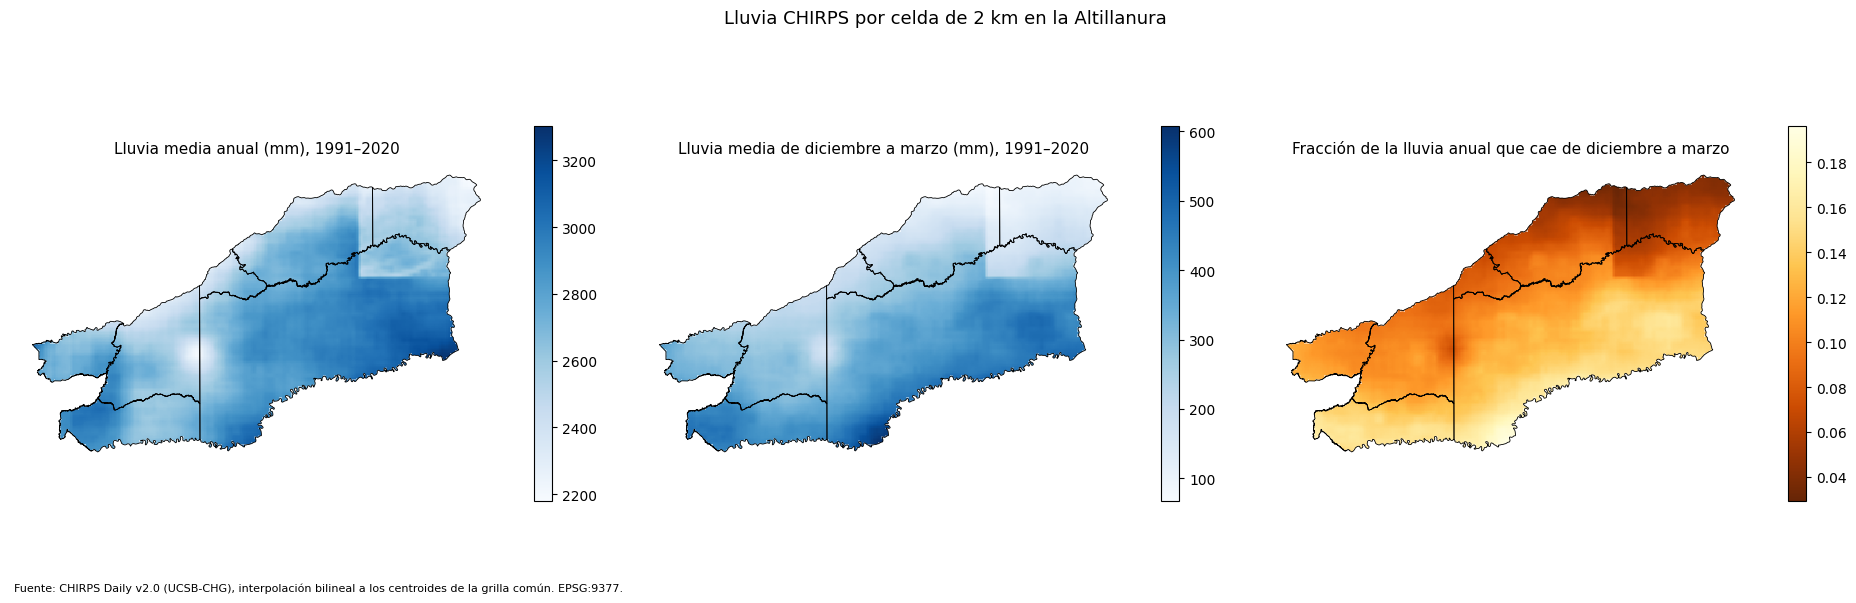

Correlación de Spearman con la posición (x = oeste→este, y = sur→norte):
  lluvia_anual_1991_2020    con x: +0.15   con y: -0.39
  lluvia_seca_1991_2020     con x: -0.12   con y: -0.74

Temporada seca 2003–2025 frente a la normal: mediana -2.4 % (p10 -5.5 %, p90 +3.7 %)


In [5]:
mapa = grilla[['id_celda', 'geometry']].merge(lluvia, on='id_celda')
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, col, titulo, cmap in [
        (axes[0], 'lluvia_anual_1991_2020', 'Lluvia media anual (mm), 1991–2020', 'Blues'),
        (axes[1], 'lluvia_seca_1991_2020', 'Lluvia media de diciembre a marzo (mm), 1991–2020', 'Blues'),
        (axes[2], 'frac_seca_1991_2020', 'Fracción de la lluvia anual que cae de diciembre a marzo', 'YlOrBr_r')]:
    mapa.plot(column=col, cmap=cmap, legend=True, ax=ax, linewidth=0,
              legend_kwds={'shrink': 0.7})
    mpios.boundary.plot(ax=ax, color='black', linewidth=0.6)
    ax.set_title(titulo, fontsize=11)
    ax.set_axis_off()
fig.suptitle('Lluvia CHIRPS por celda de 2 km en la Altillanura', fontsize=13)
fig.text(0.01, 0.01, 'Fuente: CHIRPS Daily v2.0 (UCSB-CHG), interpolación bilineal a los centroides de la grilla común. EPSG:9377.', fontsize=8)
plt.tight_layout()
plt.savefig(f'{GRAFICAS}/12_lluvia_celda.png', dpi=150, bbox_inches='tight')
plt.show()

d = lluvia.merge(grilla[['id_celda', 'x_9377', 'y_9377']], on='id_celda')
print('Correlación de Spearman con la posición (x = oeste→este, y = sur→norte):')
for col in ['lluvia_anual_1991_2020', 'lluvia_seca_1991_2020']:
    print(f"  {col:24s}  con x: {d[col].corr(d['x_9377'], method='spearman'):+.2f}   "
          f"con y: {d[col].corr(d['y_9377'], method='spearman'):+.2f}")
cambio = (lluvia['lluvia_seca_2003_2025'] / lluvia['lluvia_seca_1991_2020'] - 1) * 100
print(f'\nTemporada seca 2003–2025 frente a la normal: mediana {cambio.median():+.1f} % '
      f'(p10 {cambio.quantile(0.1):+.1f} %, p90 {cambio.quantile(0.9):+.1f} %)')

### Cómo leer los resultados

- **Mapas.** El primero muestra dónde llueve más en el año; el segundo, dónde la temporada seca es más seca (menos milímetros de diciembre a marzo); el tercero, qué tan marcada es la estación seca en cada lugar.
- **Gradiente.** Las correlaciones con `x` y `y` resumen la dirección del cambio: un valor negativo con `y` significa que llueve menos hacia el norte; uno negativo con `x`, que llueve menos hacia el oriente. Según el cuaderno 11, Cumaribo y Mapiripán (sur y suroccidente) son los más lluviosos y Puerto Carreño (nororiente) el más seco.
- **2003–2025 frente a la normal.** Indica si en el periodo de los focos la temporada seca fue más o menos lluviosa que la normal climatológica.

**Relación con el resto del proyecto.** El cuaderno 21 mostró que, mes a mes, **menos lluvia en la temporada seca significa más focos** (+5,3 % de focos por cada 10 mm menos). Esta capa permite preguntar lo mismo en el espacio: ¿las celdas con temporada seca más seca tienen más focos (`focos_celda.csv`, cuaderno 22) y más expansión agropecuaria? Eso se prueba en el cuaderno 61 con la significancia corregida por autocorrelación espacial.

**Limitaciones.**
- La resolución real es la de CHIRPS (~5 km): las celdas vecinas comparten información y sus valores no son independientes.
- CHIRPS combina satélite y estaciones, y en la Altillanura hay pocas estaciones, así que los valores absolutos tienen incertidumbre; los contrastes entre zonas son más confiables que los milímetros exactos.
- Se usa el promedio climatológico: no representa un año concreto.

### Resultados y conclusiones

**1. La validación es casi perfecta.** El promedio de las celdas de cada municipio, ponderado por área, coincide con la normal municipal del cuaderno 11 con diferencias de **0,0 % en la lluvia anual y como máximo 0,1 % en la temporada seca**. La interpolación a la grilla conserva los totales: no se pierde ni se inventa lluvia.

**2. Cuánto llueve.** La celda típica recibe **2.744 mm al año** (mediana; de 2.178 a 3.305 mm) y apenas **311 mm de diciembre a marzo** (de 67 a 609 mm). La temporada seca aporta solo el **~11 % de la lluvia anual**.

**3. El norte tiene una temporada seca mucho más marcada.**

| | Correlación con y (sur → norte) | Correlación con x (oeste → este) |
|---|---|---|
| Lluvia anual | −0,39 | +0,15 |
| Lluvia de dic–mar | **−0,74** | −0,12 |

La lluvia anual cambia poco de sur a norte, pero la de la temporada seca cae con fuerza: en la franja norte del Vichada (Puerto Carreño, La Primavera, Santa Rosalía) llegan entre ~140 y 220 mm de diciembre a marzo (promedios municipales de 137, 197 y 220 mm) y esa temporada aporta solo el 3–6 % del año; en el sur de Cumaribo y Mapiripán llegan 400–600 mm y aporta el 15–19 %. En el norte, la sabana pasa cuatro meses prácticamente sin lluvia.

**4. 2003–2025 fue algo más seco que la normal en la temporada seca:** mediana de **−2,4 %** (p10 −5,5 %, p90 +3,7 %). Es una diferencia pequeña y no indica por sí sola un cambio climático.

**5. Relación con el fuego.** El patrón coincide con lo que mostró el cuaderno 22: la franja norte, la de temporada seca más seca, es una de las zonas con más focos por km², y el sur de Cumaribo, el más lluvioso en esa temporada, es de los menos quemados. Es el mismo mecanismo del cuaderno 21 (menos lluvia, más fuego) visto en el espacio. Se prueba formalmente en el cuaderno 61, con la significancia corregida por autocorrelación espacial.

**6. Un artefacto de CHIRPS que hay que declarar.** En el nororiente (entre La Primavera y Puerto Carreño) se ve un **rectángulo de bordes rectos** con valores distintos a los de su alrededor. Un patrón así no es climático: es típico de cómo CHIRPS mezcla las estimaciones de satélite con los datos de estaciones (el área de influencia de una estación). No viene de este cuaderno, porque la validación contra el cuaderno 11 es exacta y los dos usan el mismo CHIRPS. En el cuaderno 61 conviene repetir las correlaciones excluyendo esas celdas, como análisis de sensibilidad.

**Limitaciones:** la resolución real es la de CHIRPS (~5 km), así que las celdas vecinas no son independientes; en la Altillanura hay pocas estaciones, por lo que los contrastes entre zonas son más confiables que los milímetros exactos; y es un promedio climatológico, no un año concreto.

## Paso 6. Guardar resultados

In [6]:
lluvia.round(2).to_csv(f'{COMUNES}/lluvia_celda.csv', index=False)
val.round(3).to_csv(f'{RESULTADOS}/12_validacion_municipal.csv')
print(f"Guardado: datos/comunes/lluvia_celda.csv ({os.path.getsize(f'{COMUNES}/lluvia_celda.csv') / 1e6:.1f} MB, {len(lluvia):,} filas)")

if EN_COLAB:   # descarga todo en un ZIP para subirlo al repo desde Git Bash
    import shutil
    from google.colab import files
    destino = '/content/resultados_12'
    os.makedirs(destino, exist_ok=True)
    for f in [f'{COMUNES}/lluvia_celda.csv', CACHE, f'{RESULTADOS}/12_validacion_municipal.csv',
              f'{GRAFICAS}/12_lluvia_celda.png']:
        shutil.copy(f, destino)
    shutil.make_archive(destino, 'zip', destino)
    files.download(destino + '.zip')

Guardado: datos/comunes/lluvia_celda.csv (1.6 MB, 34,763 filas)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>